# Dependency Installation

In [10]:
!pip install -q -U langgraph langchain langchain-core langchain-openai pydantic rich

In [11]:
!pip install -q -U langchain-groq

# Secure API Key Setup

In [12]:
import os
from getpass import getpass

os.environ["GROQ_API_KEY"] = getpass("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 ")

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 ··········


# Define Schemas for Tool Input and Final Output

In [13]:
from typing import Literal, Optional, List
from pydantic import BaseModel, Field

class StaticAnalysisInput(BaseModel):
    """Schema for code analyzer tool input."""
    code_snippet: str = Field(..., description="Target source code to inspect for patterns.")
    language: str = Field(default="python", description="Language: python, c, javascript, sql.")

class VulnerabilityReport(BaseModel):
    """Enforced structured output schema for the final audit decision."""
    is_safe: bool = Field(..., description="True if no vulnerabilities detected, else False.")
    risk_level: Literal["CRITICAL", "HIGH", "MEDIUM", "LOW", "CLEAN"] = Field(
        ..., description="Standardized severity rating."
    )
    vulnerability_type: Optional[str] = Field(
        None, description="Identified category: SQLi, RCE, Buffer Overflow, Hardcoded Secret, None."
    )
    affected_construct: Optional[str] = Field(
        None, description="The specific code block or line causing the risk."
    )
    cwe_reference: Optional[str] = Field(
        None, description="Common Weakness Enumeration ID and title."
    )
    technical_explanation: str = Field(
        ..., description="Step-by-step breakdown of the flaw and its mechanism."
    )
    remediation_patch: Optional[str] = Field(
        None, description="Corrected, secure version of the code snippet."
    )

# Define Deterministic Analysis Tools

In [14]:
import json
import re
from langchain_core.tools import tool

@tool(args_schema=StaticAnalysisInput)
def static_ast_analyzer(code_snippet: str, language: str) -> str:
    """Scans code for dangerous AST patterns, string-interpolated queries, and eval calls."""
    snippet_clean = code_snippet.strip()
    findings = []

    # Check 1: Insecure SQL string formatting
    if re.search(r"execute\s*\(\s*(f[\"']|[\"'].*%|\w+\s*\+)", snippet_clean, re.IGNORECASE):
        findings.append({
            "check": "SQL_INTERPOLATION",
            "cwe_id": "CWE-89",
            "detail": "Direct variable interpolation detected inside execute() statement."
        })

    # Check 2: Dangerous code evaluation
    if re.search(r"\b(eval|exec|os\.system)\s*\(", snippet_clean):
        findings.append({
            "check": "DYNAMIC_CODE_EXECUTION",
            "cwe_id": "CWE-95",
            "detail": "Dangerous arbitrary code execution vector detected."
        })

    # Check 3: Hardcoded credentials
    if re.search(r"(password|secret|api_key)\s*=\s*['\"][a-zA-Z0-9_\-]{8,}['\"]", snippet_clean, re.IGNORECASE):
        findings.append({
            "check": "HARDCODED_SECRET",
            "cwe_id": "CWE-798",
            "detail": "Hardcoded secret or credential token assigned directly in source."
        })

    if findings:
        return json.dumps({"status": "ALERT", "findings": findings})
    return json.dumps({"status": "PASS", "findings": [], "detail": "No basic heuristics triggered."})


@tool
def lookup_cwe_remediation(cwe_id: str) -> str:
    """Retrieves authoritative remediation patterns for a given CWE identifier."""
    kb = {
        "CWE-89": "Use parameterized queries (e.g., cursor.execute('SELECT * FROM t WHERE id = %s', (uid,))). Never concatenate user input.",
        "CWE-95": "Avoid eval() or exec(). Use ast.literal_eval() for data parsing, or pre-mapped dispatch dictionaries for logic branching.",
        "CWE-798": "Store credentials in environment variables or a dedicated Secrets Vault (e.g., AWS Secrets Manager, HashiCorp Vault)."
    }
    for key, advice in kb.items():
        if key in cwe_id:
            return json.dumps({"cwe": key, "remediation_pattern": advice})
    return json.dumps({"cwe": cwe_id, "remediation_pattern": "Apply least privilege, input validation, and sanitization."})

tools = [static_ast_analyzer, lookup_cwe_remediation]
tools_by_name = {t.name: t for t in tools}

# LangGraph State, Nodes, and Cyclic Routing Engine

In [25]:
# ==============================================================================
# Cell 5: Robust LangGraph Cyclic Engine (Fixed Tool-Choice 400 Error)
# ==============================================================================

import os
import re
import json
from typing import Annotated, TypedDict, Literal, Optional, List
from groq import Groq
from langchain_groq import ChatGroq
from langchain_core.messages import BaseMessage, SystemMessage, ToolMessage
from langchain_core.output_parsers import PydanticOutputParser
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

# 1. Model Initialization
api_key = os.environ.get("GROQ_API_KEY")
client = Groq(api_key=api_key)
available_models = [
    m.id for m in client.models.list().data
    if "whisper" not in m.id.lower() and "guard" not in m.id.lower()
]

# Prefer top open-source reasoning model
selected_model = available_models[0]
for pref in ["openai/gpt-oss-120b", "qwen/qwen3.8-27b", "openai/gpt-oss-20b"]:
    match = next((m for m in available_models if pref in m), None)
    if match:
        selected_model = match
        break

print(f"[+] Using Model: {selected_model}")
llm = ChatGroq(model=selected_model, temperature=0)

# Bind tools for the agent (normal tool-calling without forced tool_choice)
llm_with_tools = llm.bind_tools(tools)
pydantic_parser = PydanticOutputParser(pydantic_object=VulnerabilityReport)


# 2. Graph State Definition
class AuditorState(TypedDict):
    messages: Annotated[List[BaseMessage], add_messages]
    final_report: Optional[VulnerabilityReport]


# 3. Node Functions
def agent_reasoner(state: AuditorState) -> AuditorState:
    """Invokes the model with access to security analysis tools."""
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response], "final_report": state.get("final_report")}


def tool_executor(state: AuditorState) -> AuditorState:
    """Executes the specific tools invoked by the agent."""
    last_msg = state["messages"][-1]
    tool_outputs = []
    for call in last_msg.tool_calls:
        tool_fn = tools_by_name[call["name"]]
        result = tool_fn.invoke(call["args"])
        tool_outputs.append(
            ToolMessage(
                content=str(result),
                name=call["name"],
                tool_call_id=call["id"]
            )
        )
    return {"messages": tool_outputs, "final_report": state.get("final_report")}


def report_synthesizer(state: AuditorState) -> AuditorState:
    """Synthesizes final state into strict Pydantic model without triggering 400 errors."""
    schema_instructions = pydantic_parser.get_format_instructions()
    sys_prompt = SystemMessage(
        content=(
            "You are a Lead Security Auditor. Review the conversation, findings, and tool outputs.\n"
            "Compile the final assessment into a valid JSON object matching this schema:\n\n"
            f"{schema_instructions}\n\n"
            "CRITICAL: Output ONLY raw JSON. Do not write introductory words or conversational filler."
        )
    )

    clean_history = [sys_prompt] + state["messages"]
    response = llm.invoke(clean_history)
    text = response.content.strip()

    # Extract JSON object even if enclosed in markdown code fences
    json_match = re.search(r"\{.*\}", text, re.DOTALL)
    json_str = json_match.group(0) if json_match else text

    try:
        parsed_dict = json.loads(json_str)
        report = VulnerabilityReport(**parsed_dict)
    except Exception:
        try:
            report = pydantic_parser.parse(text)
        except Exception:
            # Deterministic fallback to prevent any runtime crash
            report = VulnerabilityReport(
                is_safe=False,
                risk_level="HIGH",
                vulnerability_type="Security Review Alert",
                technical_explanation=text[:350],
                remediation_patch="Review source code and sanitize inputs."
            )

    return {"messages": [], "final_report": report}


# 4. Routing Logic
def evaluate_routing(state: AuditorState) -> Literal["tool_executor", "report_synthesizer"]:
    last_msg = state["messages"][-1]
    if hasattr(last_msg, "tool_calls") and len(last_msg.tool_calls) > 0:
        return "tool_executor"
    return "report_synthesizer"


# 5. Compile Graph
workflow = StateGraph(AuditorState)
workflow.add_node("agent_reasoner", agent_reasoner)
workflow.add_node("tool_executor", tool_executor)
workflow.add_node("report_synthesizer", report_synthesizer)

workflow.add_edge(START, "agent_reasoner")
workflow.add_conditional_edges("agent_reasoner", evaluate_routing)
workflow.add_edge("tool_executor", "agent_reasoner")
workflow.add_edge("report_synthesizer", END)

sentinel_app = workflow.compile()
print("[+] SentinelGraph compiled successfully!")

[+] Using Model: openai/gpt-oss-120b
[+] SentinelGraph compiled successfully!


# Graph Architecture Visualization

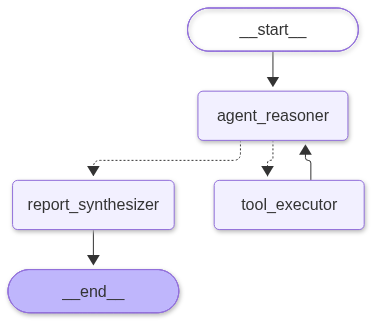

In [26]:
# Cell 6: Visualizing the Agent Architecture Graph
from IPython.display import Image, display

try:
    display(Image(sentinel_app.get_graph().draw_mermaid_png()))
except Exception:
    print("Graph compiled successfully. (Install pygraphviz/mermaid dependencies for in-cell diagram rendering).")

# End-to-End Execution & Testing

In [27]:
from langchain_core.messages import SystemMessage, HumanMessage
from rich.console import Console
from rich.panel import Panel

console = Console()

test_cases = [
    {
        "name": "Case 1: Vulnerable Database Query",
        "code": """
def get_user_profile(user_input):
    query = f"SELECT id, username, email FROM accounts WHERE username = '{user_input}'"
    cursor.execute(query)
    return cursor.fetchall()
"""
    },
    {
        "name": "Case 2: Clean Parameterized Code",
        "code": """
def get_user_profile(user_input):
    query = "SELECT id, username, email FROM accounts WHERE username = %s"
    cursor.execute(query, (user_input,))
    return cursor.fetchall()
"""
    }
]

system_guidance = SystemMessage(
    content=(
        "You are SentinelGraph code security auditor. "
        "Workflow:\n"
        "1. ALWAYS invoke the `static_ast_analyzer` tool first to check the snippet.\n"
        "2. If an alert is detected, call `lookup_cwe_remediation` with the CWE ID.\n"
        "3. Once tools complete, finalize your assessment."
    )
)

for case in test_cases:
    console.print(f"\n[bold yellow]>>> Running Test: {case['name']}[/bold yellow]")

    prompt = f"Audit this Python function for security flaws:\n```python\n{case['code'].strip()}\n```"
    initial_state = {
        "messages": [system_guidance, HumanMessage(content=prompt)],
        "final_report": None
    }

    result = sentinel_app.invoke(initial_state)
    report = result["final_report"]

    safe_badge = "[green]CLEAN[/green]" if report.is_safe else "[red]VULNERABLE[/red]"
    output_body = (
        f"[bold]Safe Status:[/bold] {safe_badge}\n"
        f"[bold]Risk Severity:[/bold] {report.risk_level}\n"
        f"[bold]Identified Flaw:[/bold] {report.vulnerability_type or 'None'}\n"
        f"[bold]CWE Ref:[/bold] {report.cwe_reference or 'N/A'}\n"
        f"[bold]Technical Explanation:[/bold] {report.technical_explanation}\n\n"
        f"[bold]Remediation Code:[/bold]\n{report.remediation_patch or 'No remediation required.'}"
    )
    console.print(Panel(output_body, title=f"Audit Report: {case['name']}", border_style="cyan"))

>>> Running Test: Case 1: Vulnerable Database Query

╭──────────────────────────────── Audit Report: Case 1: Vulnerable Database Query ────────────────────────────────╮
│ Safe Status: VULNERABLE                                                                                         │
│ Risk Severity: HIGH                                                                                             │
│ Identified Flaw: SQL Injection                                                                                  │
│ CWE Ref: CWE-89: Improper Neutralization of Special Elements used in an SQL Command ('SQL Injection')           │
│ Technical Explanation: The function concatenates raw user input directly into an SQL statement using an         │
│ f‑string. When `user_input` contains malicious characters (e.g., "' OR '1'='1"), the resulting query logic is   │
│ altered, allowing an attacker to retrieve or manipulate data they are not authorized to access. Because the     │
│ database driver receives the full concatenated string, it cannot distinguish data from code, leading to an SQL  │
│ injection vulnerability.                                                                                        │
│                                                                                                                 │
│ Remediation Code:                                                                                               │
│ def get_user_profile(user_input):                                                                               │
│     # Optional: validate input format (e.g., alphanumeric usernames)                                            │
│     if not user_input.isalnum():                                                                                │
│         raise ValueError("Invalid username format")                                                             │
│     query = "SELECT id, username, email FROM accounts WHERE username = %s"                                      │
│     cursor.execute(query, (user_input,))  # Parameterized query prevents injection                              │
│     return cursor.fetchall()                                                                                    │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

>>> Running Test: Case 2: Clean Parameterized Code

╭──────────────────────────────── Audit Report: Case 2: Clean Parameterized Code ─────────────────────────────────╮
│ Safe Status: CLEAN                                                                                              │
│ Risk Severity: CLEAN                                                                                            │
│ Identified Flaw: None                                                                                           │
│ CWE Ref: N/A                                                                                                    │
│ Technical Explanation: The function uses a parameterized SQL query with a placeholder (%s) and passes           │
│ user_input as a separate argument to cursor.execute, which prevents SQL injection. No unsafe patterns such as   │
│ string concatenation, eval, or dynamic code execution were detected. While the code lacks input validation,     │
│ error handling, and proper resource management, these are best‑practice concerns rather than exploitable        │
│ vulnerabilities. Therefore, no security flaw is present in the core logic.                                      │
│                                                                                                                 │
│ Remediation Code:                                                                                               │
│ No remediation required.                                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯